In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#Chargement des données 
df =pd.read_csv("Auto Sales data.csv")

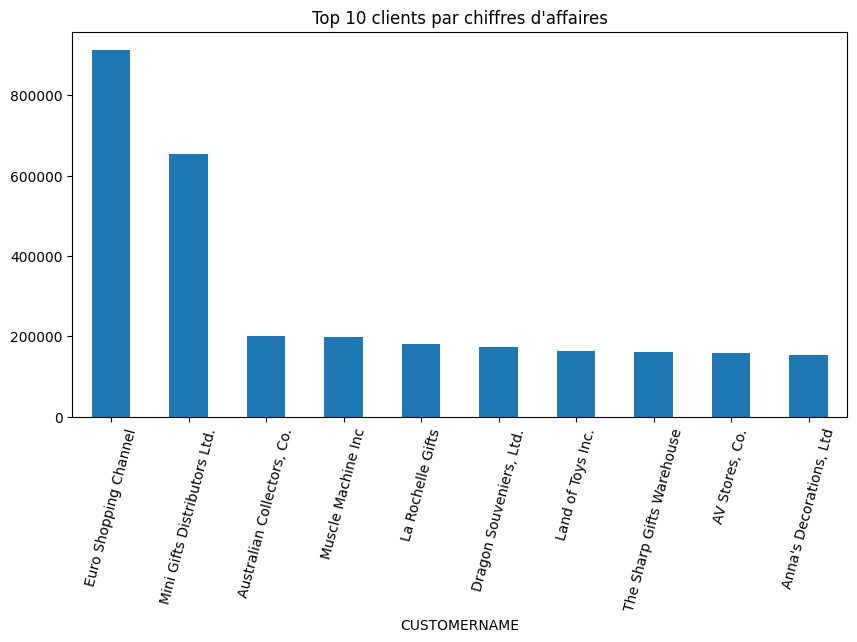

In [3]:
#Chiffre d'affaires par client
top_clients = df.groupby("CUSTOMERNAME")["SALES"].sum().sort_values(ascending=False).head(10)

top_clients.plot(kind="bar" , figsize=(10,5))
plt.title("Top 10 clients par chiffres d'affaires")
plt.xticks(rotation=75)
plt.show()

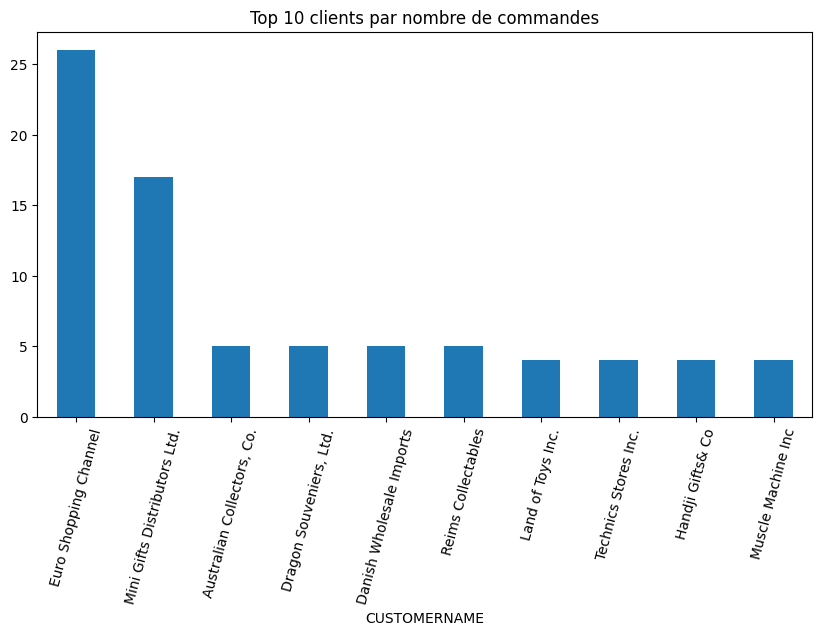

In [4]:
#Nombre de commandes par client
client_orders = df.groupby("CUSTOMERNAME")["ORDERNUMBER"].nunique().sort_values(ascending=False).head(10)

client_orders.plot(kind="bar", figsize=(10,5))
plt.title("Top 10 clients par nombre de commandes")
plt.xticks(rotation=75)
plt.show()

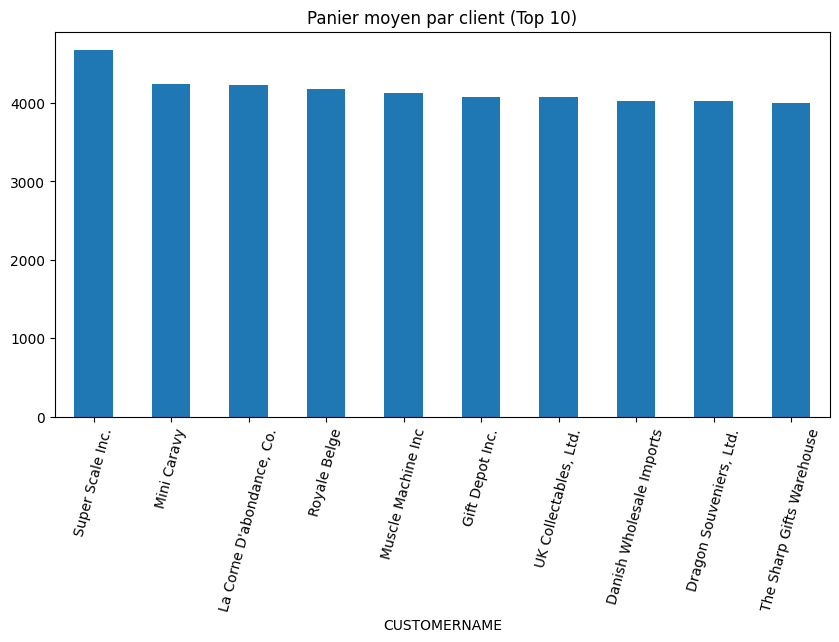

In [5]:
#Panier moyen par client
client_avg = df.groupby("CUSTOMERNAME")["SALES"].mean().sort_values(ascending=False).head(10)

client_avg.plot(kind="bar", figsize=(10,5))
plt.title("Panier moyen par client (Top 10)")
plt.xticks(rotation=75)
plt.show()

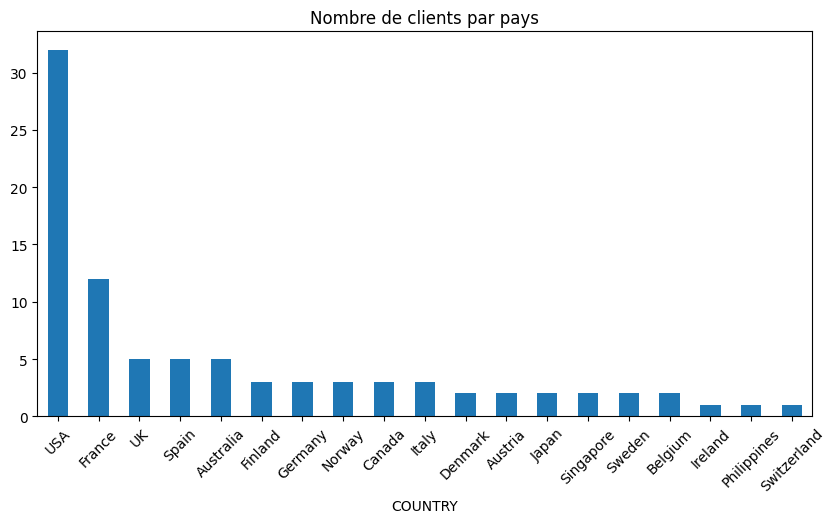

In [6]:
#Analyse des clients par pays
clients_by_country = df.groupby("COUNTRY")["CUSTOMERNAME"].nunique().sort_values(ascending=False)

clients_by_country.plot(kind="bar", figsize=(10,5))
plt.title("Nombre de clients par pays")
plt.xticks(rotation=45)
plt.show()

In [9]:
#RFM Analysis
import datetime as dt

df['ORDERDATE'] = pd.to_datetime(df['ORDERDATE'])

# date de référence
reference_date = df["ORDERDATE"].max() + dt.timedelta(days=1)

rfm = df.groupby("CUSTOMERNAME").agg({
    "ORDERDATE": lambda x: (reference_date - x.max()).days,  # Recency
    "ORDERNUMBER": "nunique",                               # Frequency
    "SALES": "sum"                                           # Monetary
})

rfm.rename(columns={
    "ORDERDATE": "Recency",
    "ORDERNUMBER": "Frequency",
    "SALES": "Monetary"
}, inplace=True)

rfm.head(10)

,Recency,Frequency,Monetary
CUSTOMERNAME,,,
"AV Stores, Co.",197,3,157807.81
Alpha Cognac,65,3,70488.44
Amica Models & Co.,266,2,94117.26
"Anna's Decorations, Ltd",84,4,153996.13
Atelier graphique,189,3,24179.96
"Australian Collectables, Ltd",23,3,64591.46
"Australian Collectors, Co.",185,5,200995.41
"Australian Gift Network, Co",120,3,59469.12
Auto Assoc. & Cie.,234,2,64834.32


In [10]:
#Score RFM
rfm["R_score"] = pd.qcut(rfm["Recency"], 4, labels=[4,3,2,1])
rfm["F_score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1,2,3,4])
rfm["M_score"] = pd.qcut(rfm["Monetary"], 4, labels=[1,2,3,4])

rfm["RFM_Score"] = rfm["R_score"].astype(str) + rfm["F_score"].astype(str) + rfm["M_score"].astype(str)

rfm.head(10)

,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_Score
CUSTOMERNAME,,,,,,,
"AV Stores, Co.",197,3,157807.81,2,2,4,224
Alpha Cognac,65,3,70488.44,4,2,1,421
Amica Models & Co.,266,2,94117.26,1,1,3,113
"Anna's Decorations, Ltd",84,4,153996.13,3,4,4,344
Atelier graphique,189,3,24179.96,2,2,1,221
"Australian Collectables, Ltd",23,3,64591.46,4,2,1,421
"Australian Collectors, Co.",185,5,200995.41,3,4,4,344
"Australian Gift Network, Co",120,3,59469.12,3,2,1,321
Auto Assoc. & Cie.,234,2,64834.32,1,1,1,111


In [11]:
#Visualisation simple RFM
rfm[["Recency","Frequency","Monetary"]].describe()

,Recency,Frequency,Monetary
count,89.000000,89.000000,89.000000
mean,180.606742,3.348315,109665.412472
std,128.893862,2.969929,111837.420467
min,1.000000,1.000000,9129.350000
25%,76.000000,2.000000,70488.440000
50%,185.000000,3.000000,87489.230000
75%,231.000000,3.000000,120562.740000
max,496.000000,26.000000,912294.110000


In [12]:
#Top clients
rfm.sort_values("Monetary", ascending=False).head(10)

,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_Score
CUSTOMERNAME,,,,,,,
Euro Shopping Channel,1,26,912294.11,4,4,4,444
Mini Gifts Distributors Ltd.,3,17,654858.06,4,4,4,444
"Australian Collectors, Co.",185,5,200995.41,3,4,4,344
Muscle Machine Inc,183,4,197736.94,3,4,4,344
La Rochelle Gifts,1,4,180124.90,4,4,4,444
"Dragon Souveniers, Ltd.",91,5,172989.68,3,4,4,344
Land of Toys Inc.,199,4,164069.44,2,4,4,244
The Sharp Gifts Warehouse,40,4,160010.27,4,4,4,444
"AV Stores, Co.",197,3,157807.81,2,2,4,224
